In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib
import os
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


Load Dataset

In [3]:
df = pd.read_csv("../dataset/accurate_ballastic.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (10000, 7)


,velocity,angle_deg,gravity,range_actual,max_height_actual,range_noisy,max_height_noisy
0,562.178083,36.154857,9.816500,30672.787977,5602.999158,29705.533378,5665.662956
1,965.500014,33.303847,9.789226,87399.318226,14354.755375,96752.394634,14920.923866
2,812.395759,22.330774,9.797332,47351.292203,4862.474340,51294.895046,4851.801426
3,719.060939,52.508667,9.813164,50889.816882,16585.419167,52749.675402,15581.543014
4,409.213048,43.363691,9.804104,17052.269848,4026.268147,16759.758681,4162.781928


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Number of rows: 10000
Number of columns: 7

Columns:
['velocity', 'angle_deg', 'gravity', 'range_actual', 'max_height_actual', 'range_noisy', 'max_height_noisy']

Data types:
velocity             float64
angle_deg            float64
gravity              float64
range_actual         float64
max_height_actual    float64
range_noisy          float64
max_height_noisy     float64
dtype: object


Check missing values

In [5]:
print("Missing values in each column:\n")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:

velocity             0
angle_deg            0
gravity              0
range_actual         0
max_height_actual    0
range_noisy          0
max_height_noisy     0
dtype: int64

Total missing values: 0


In [6]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [7]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (10000, 7)


In [8]:
display(df.describe())

,velocity,angle_deg,gravity,range_actual,max_height_actual,range_noisy,max_height_noisy
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,645.911690,45.317091,9.805003,35888.399367,11764.862785,35875.880898,11767.679933
std,201.341089,20.250619,0.014339,23319.005073,10622.240482,23405.560875,10655.929445
min,300.008144,10.011042,9.780002,3458.994784,161.466824,3525.857198,161.767376
25%,472.430208,27.776206,9.792687,16320.303909,3554.789804,16294.874807,3537.249312
50%,644.770032,45.412774,9.805103,30560.778006,8154.159896,30512.095815,8138.315123
75%,818.004444,62.953545,9.817234,50999.182949,17275.152985,50832.961890,17265.741068
max,999.802371,79.994738,9.829995,101627.531142,49034.311754,109046.708663,54258.518945



Check target distributions

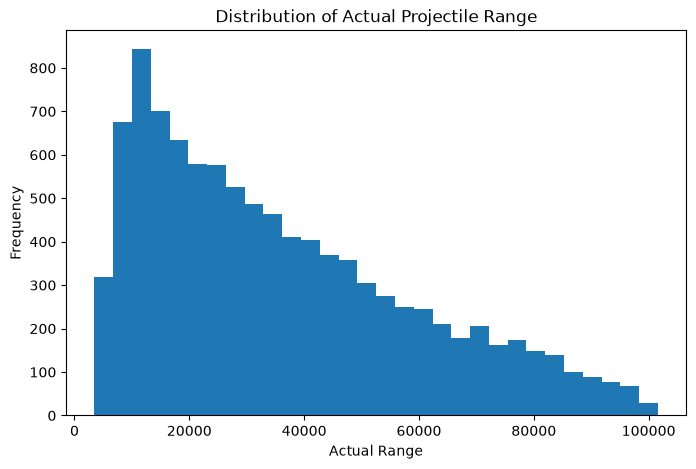

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df["range_actual"], bins=30)

plt.xlabel("Actual Range")
plt.ylabel("Frequency")
plt.title("Distribution of Actual Projectile Range")

plt.show()

Maximum height distribution

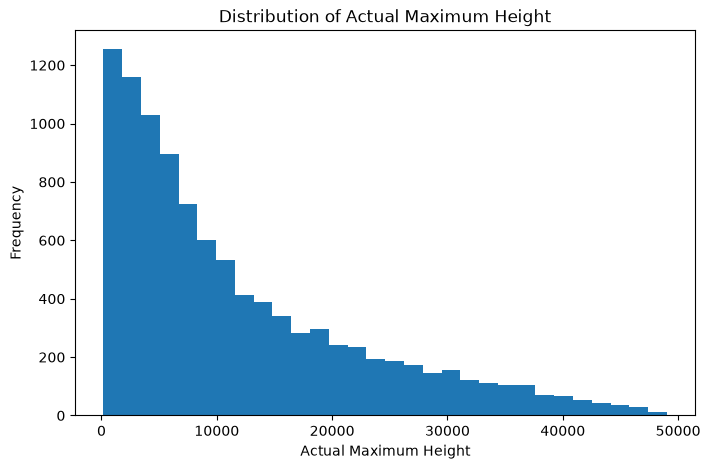

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(df["max_height_actual"], bins=30)

plt.xlabel("Actual Maximum Height")
plt.ylabel("Frequency")
plt.title("Distribution of Actual Maximum Height")

plt.show()

Velocity vs range

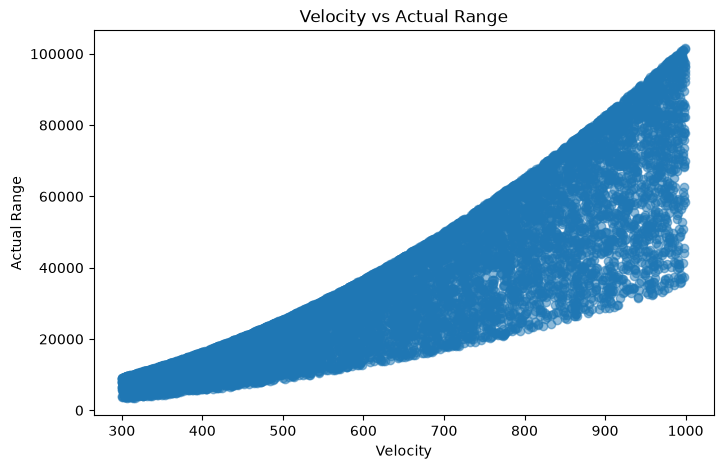

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["velocity"],
    df["range_actual"],
    alpha=0.5
)

plt.xlabel("Velocity")
plt.ylabel("Actual Range")
plt.title("Velocity vs Actual Range")

plt.show()

Angle vs range

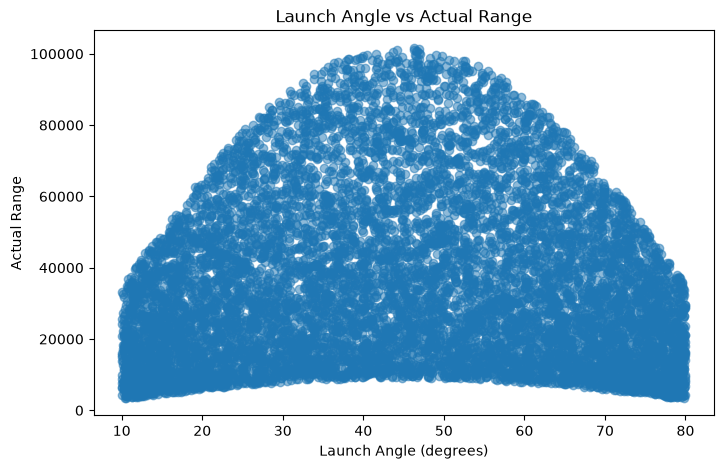

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["angle_deg"],
    df["range_actual"],
    alpha=0.5
)

plt.xlabel("Launch Angle (degrees)")
plt.ylabel("Actual Range")
plt.title("Launch Angle vs Actual Range")

plt.show()

Velocity vs maximum height

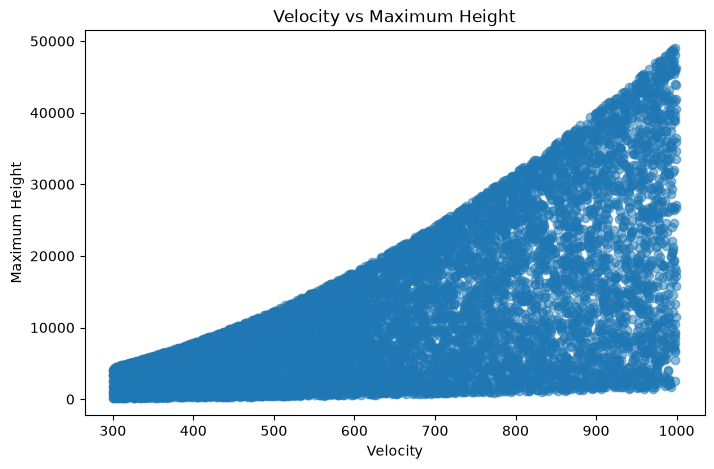

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["velocity"],
    df["max_height_actual"],
    alpha=0.5
)

plt.xlabel("Velocity")
plt.ylabel("Maximum Height")
plt.title("Velocity vs Maximum Height")

plt.show()

Correlation analysis


In [14]:
correlation = df.corr(numeric_only=True)


display(correlation)

,velocity,angle_deg,gravity,range_actual,max_height_actual,range_noisy,max_height_noisy
velocity,1.000000,-0.005125,-0.009346,0.879001,0.631286,0.875310,0.630206
angle_deg,-0.005125,1.000000,-0.024219,-0.008632,0.662334,-0.008641,0.659641
gravity,-0.009346,-0.024219,1.000000,-0.006116,-0.019343,-0.007250,-0.019671
range_actual,0.879001,-0.008632,-0.006116,1.000000,0.562184,0.995796,0.561826
max_height_actual,0.631286,0.662334,-0.019343,0.562184,1.000000,0.559555,0.997220
range_noisy,0.875310,-0.008641,-0.007250,0.995796,0.559555,1.000000,0.559072
max_height_noisy,0.630206,0.659641,-0.019671,0.561826,0.997220,0.559072,1.000000


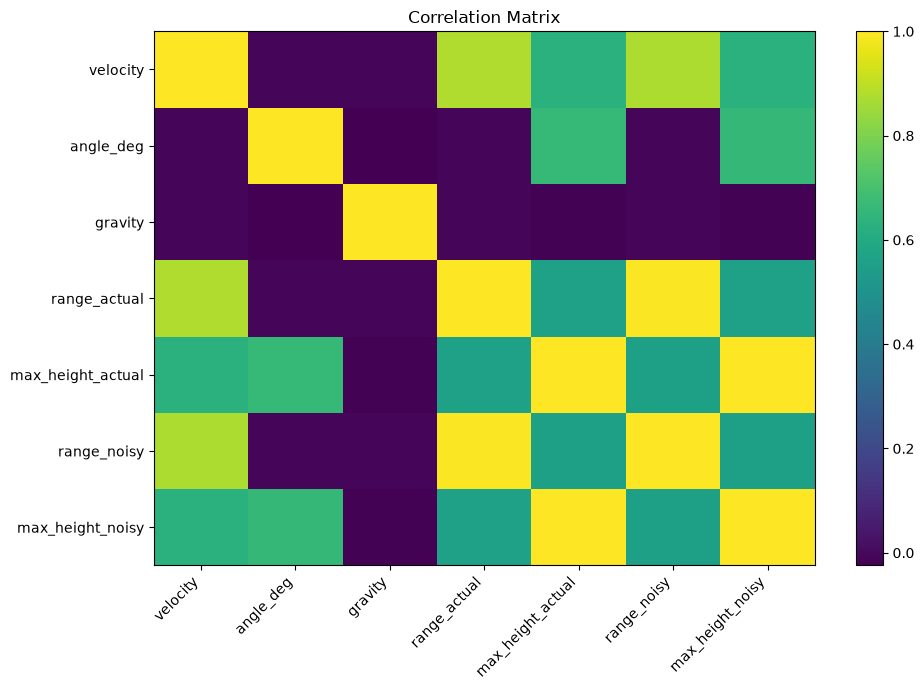

In [15]:
plt.figure(figsize=(10, 7))

plt.imshow(correlation, aspect="auto")

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")

plt.tight_layout()

plt.show()


Define features and targets

In [16]:
features = [
    "velocity",
    "angle_deg",
    "gravity"
]

X = df[features]

y_range = df["range_actual"]

y_height = df["max_height_actual"]

print("Input features:")
print(features)

print("\nRange target:", "range_actual")
print("Height target:", "max_height_actual")

Input features:
['velocity', 'angle_deg', 'gravity']

Range target: range_actual
Height target: max_height_actual



Train/test split

In [17]:
X_train, X_test, y_range_train, y_range_test, y_height_train, y_height_test = train_test_split(
    X,
    y_range,
    y_height,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


Preprocessing pipeline

In [18]:
preprocessor = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

Create ML models

In [19]:
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=10,
                random_state=42
            )
        )
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=15,
                random_state=42,
                n_jobs=-1
            )
        )
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ])
}

print("Models created:")
for name in models:
    print("-", name)

Models created:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting


Evaluation function

In [20]:
def evaluate_model(model, X_train, X_test, y_train, y_test):

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    mse = mean_squared_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        predictions
    )

    return mae, mse, rmse, r2, predictions

Train models for RANGE

In [21]:
range_results = []

range_predictions = {}

for name, model in models.items():

    mae, mse, rmse, r2, predictions = evaluate_model(
        model,
        X_train,
        X_test,
        y_range_train,
        y_range_test
    )

    range_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    range_predictions[name] = predictions

range_results_df = pd.DataFrame(range_results)

range_results_df = range_results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

display(range_results_df)

,Model,MAE,MSE,RMSE,R2
0,Random Forest,256.370861,1.425209e+05,377.519386,0.999740
1,Gradient Boosting,637.878599,6.917426e+05,831.710632,0.998740
2,Decision Tree,1072.754810,2.116797e+06,1454.921597,0.996145
3,Linear Regression,8570.960722,1.241448e+08,11142.030720,0.773897


Train models for MAXIMUM HEIGHT

In [22]:
height_results = []

height_predictions = {}

for name, model in models.items():

    mae, mse, rmse, r2, predictions = evaluate_model(
        model,
        X_train,
        X_test,
        y_height_train,
        y_height_test
    )

    height_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    height_predictions[name] = predictions

height_results_df = pd.DataFrame(height_results)

height_results_df = height_results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

display(height_results_df)

,Model,MAE,MSE,RMSE,R2
0,Random Forest,80.839870,1.759950e+04,132.663113,0.999849
1,Gradient Boosting,249.058868,1.133347e+05,336.652169,0.999025
2,Decision Tree,288.759589,1.700122e+05,412.325400,0.998537
3,Linear Regression,3286.984321,1.816088e+07,4261.558250,0.843733



Best models

In [23]:
best_range_model_name = range_results_df.iloc[0]["Model"]

best_height_model_name = height_results_df.iloc[0]["Model"]

print("Best model for Range:")
print(best_range_model_name)

print("\nBest model for Maximum Height:")

print(best_height_model_name)

Best model for Range:
Random Forest

Best model for Maximum Height:
Random Forest


5-Fold Cross Validation

In [24]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [25]:
cv_range_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y_range,
        cv=kf,
        scoring="r2",
        n_jobs=-1
    )

    cv_range_results.append({
        "Model": name,
        "Mean R2": scores.mean(),
        "Std R2": scores.std()
    })

cv_range_df = pd.DataFrame(cv_range_results)

cv_range_df = cv_range_df.sort_values(
    by="Mean R2",
    ascending=False
)


display(cv_range_df)

,Model,Mean R2,Std R2
2,Random Forest,0.999736,0.000016
3,Gradient Boosting,0.998709,0.000049
1,Decision Tree,0.996167,0.000164
0,Linear Regression,0.772513,0.001014


Height cross-validation

In [26]:
cv_height_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y_height,
        cv=kf,
        scoring="r2",
        n_jobs=-1
    )

    cv_height_results.append({
        "Model": name,
        "Mean R2": scores.mean(),
        "Std R2": scores.std()
    })

cv_height_df = pd.DataFrame(cv_height_results)

cv_height_df = cv_height_df.sort_values(
    by="Mean R2",
    ascending=False
)

display(cv_height_df)

,Model,Mean R2,Std R2
2,Random Forest,0.999856,0.000014
3,Gradient Boosting,0.998987,0.000085
1,Decision Tree,0.998625,0.000061
0,Linear Regression,0.841249,0.002983


Actual vs predicted Range

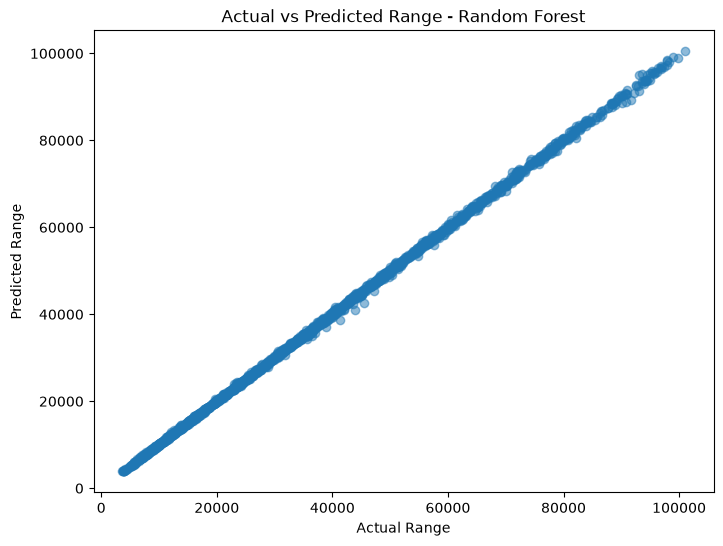

In [27]:
best_range_predictions = range_predictions[
    best_range_model_name
]

plt.figure(figsize=(8, 6))

plt.scatter(
    y_range_test,
    best_range_predictions,
    alpha=0.5
)

plt.xlabel("Actual Range")
plt.ylabel("Predicted Range")

plt.title(
    f"Actual vs Predicted Range - {best_range_model_name}"
)

plt.show()

Actual vs predicted Height

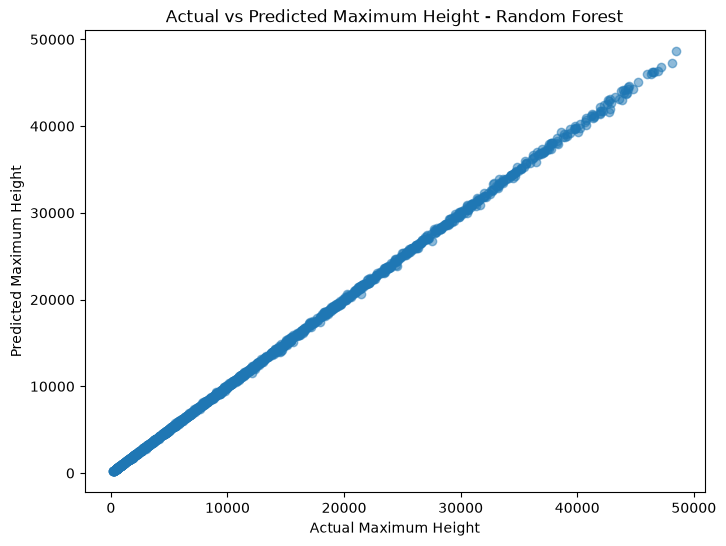

In [28]:
best_height_predictions = height_predictions[
    best_height_model_name
]

plt.figure(figsize=(8, 6))

plt.scatter(
    y_height_test,
    best_height_predictions,
    alpha=0.5
)

plt.xlabel("Actual Maximum Height")
plt.ylabel("Predicted Maximum Height")

plt.title(
    f"Actual vs Predicted Maximum Height - {best_height_model_name}"
)

plt.show()

Calculate prediction errors

In [29]:
range_error = y_range_test.values - best_range_predictions

range_absolute_error = np.abs(range_error)

range_percentage_error = (
    range_absolute_error /
    np.abs(y_range_test.values)
) * 100

print(
    "Average Range Absolute Error:",
    range_absolute_error.mean()
)

print(
    "Average Range Percentage Error:",
    range_percentage_error.mean(),
    "%"
)

Average Range Absolute Error: 256.37086115253476
Average Range Percentage Error: 0.8582958959708413 %


In [30]:
height_error = y_height_test.values - best_height_predictions

height_absolute_error = np.abs(height_error)

height_percentage_error = (
    height_absolute_error /
    np.abs(y_height_test.values)
) * 100

print(
    "Average Height Absolute Error:",
    height_absolute_error.mean()
)

print(
    "Average Height Percentage Error:",
    height_percentage_error.mean(),
    "%"
)

Average Height Absolute Error: 80.83987010426267
Average Height Percentage Error: 0.9429104261584632 %


In [31]:
os.makedirs("../models", exist_ok=True)

In [32]:
best_range_model = models[
    best_range_model_name
]

best_height_model = models[
    best_height_model_name
]

best_range_model.fit(
    X,
    y_range
)

best_height_model.fit(
    X,
    y_height
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['velocity','angle_deg','gravity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_c

In [33]:
joblib.dump(
    best_range_model,
    "../models/range_model.pkl"
)

joblib.dump(
    best_height_model,
    "../models/height_model.pkl"
)
joblib.dump(
    list(X.columns),
    "../models/features.pkl"
)
print("Models saved successfully!")

Models saved successfully!


In [34]:
new_projectile = pd.DataFrame({
    "velocity": [500],
    "angle_deg": [45],
    "gravity": [9.81]
})

predicted_range = best_range_model.predict(
    new_projectile
)[0]

predicted_height = best_height_model.predict(
    new_projectile
)[0]

print("Input:")
display(new_projectile)

print("Predicted Range:", predicted_range)

print("Predicted Maximum Height:", predicted_height)

Input:


,velocity,angle_deg,gravity
0,500,45,9.81


Predicted Range: 6438.6172295470315
Predicted Maximum Height: 6438.6172295470315
